# 02 — Spot-checking de algoritmos

**CMP263 (PPGC/UFRGS, 2026/2)** · Grupo: Artur Mariano, Emerson Herrera e Yaser Husein

**Pergunta:** entre algoritmos com vieses indutivos diferentes e **hiperparâmetros padrão**, quais predizem melhor o desempenho médio das escolas no ENEM 2025? Quais merecem a otimização de hiperparâmetros (nested CV) numa etapa seguinte?

Este notebook é o *spot-checking* recomendado no enunciado: uma triagem rápida e **sem ajuste de hiperparâmetros**, para escolher quais algoritmos otimizar depois. Todos os algoritmos usam **os mesmos dados, o mesmo pré-processamento (`build_preprocessor`) e as mesmas dobras (`assign_folds`)**, via `spot_check` de `src/enem_school/evaluation.py`.

| Item | Escolha |
|---|---|
| Unidade | escola com ≥ 10 candidatos presentes nas 4 provas (23.374 escolas) |
| Alvo | `nota_media`: média, por escola, da média das 5 notas |
| Atributos | variante **A** (43 atributos do Censo Escolar 2024 + 2 indicadores do código 88888) |
| Validação | 5 dobras por município × 3 repetições = **15 medições** por algoritmo; as mesmas partições para todos |
| Métricas | RMSE (principal), MAE (em pontos do ENEM) e R²; tempo de treino em segundos |
| Análise estatística | teste de Friedman + pós-teste de Nemenyi (Aula 08) sobre o RMSE |

### Reprodutibilidade

- Os dados vêm de `scripts/build_dataset.py`, que registra a URL e o SHA-256 de cada arquivo do INEP. A seção 2 confere esses hashes.
- As versões das bibliotecas estão fixadas em `uv.lock` / `requirements.txt`. A última seção imprime as versões usadas na execução.
- As dobras vêm de `assign_folds(schools, repeticao)`, que embaralha os municípios com `config.SEED + repeticao`: todos os notebooks usam exatamente as mesmas dobras.
- Os algoritmos com sorteio interno (árvore, floresta, *boosting*) recebem `random_state=config.SEED`.
- Os **tempos de treino dependem da máquina** e não são reprodutíveis bit a bit; as métricas são.
- Para rodar de novo: **Kernel → Restart & Run All** (local) ou **Ambiente de execução → Executar tudo** (Colab). O SVR é o passo mais lento: a execução completa pode levar dezenas de minutos.

## 1. Ambiente

A célula abaixo funciona **localmente** e **no Google Colab**:

- **Local:** rode a partir da raiz do repositório, depois de `uv sync --group notebooks`, e abra com `uv run jupyter lab`.
- **Colab:** a célula clona o repositório e instala as versões fixadas em `requirements.txt`. Se o Colab avisar que precisa reiniciar a sessão (por trocar a versão do pandas/numpy), reinicie e rode tudo de novo.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/emersonheto/enem-school-performance.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo = Path("/content/enem-school-performance")
    if not repo.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo)], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Raiz do repositório: funciona com o notebook aberto em notebooks/ ou na raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
print("Raiz do repositório:", ROOT.name)
print("Colab:", IN_COLAB)

Raiz do repositório: enem-school-performance
Colab: False


In [2]:
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

from enem_school import config
from enem_school.evaluation import compare_algorithms, spot_check
from enem_school.preprocessing import N_REPEATS

random.seed(config.SEED)
np.random.seed(config.SEED)
pd.set_option("display.precision", 2)

RESULTS_DIR = config.REPORTS_DIR / "results"
FIGURES_DIR = config.REPORTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2. Dados

A tabela por escola é gerada por `scripts/build_dataset.py`. Se ela ainda não existir (por exemplo, numa sessão nova do Colab), a célula abaixo roda o script, que **baixa cerca de 1 GB do INEP** e leva alguns minutos.

Em seguida conferimos o SHA-256 dos arquivos brutos registrados nos metadados. Se o INEP republicar os microdados, os hashes mudam e a célula falha. Assim, nunca comparamos sem perceber resultados obtidos com dados diferentes.

In [3]:
if not config.SCHOOL_TABLE.exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "build_dataset.py")], check=True, cwd=ROOT)

EXPECTED_SHA256 = {
    "enem": "b8d3e72cbf387ee08f18d552367005429017d43eea1f6d4b9bafe1d83a116071",
    "censo": "ae29d81d45ddecef59e11eda39788cbfd30dfa1cc71be9d29f23051fc2d640db",
}
metadata = json.loads(config.SCHOOL_TABLE_METADATA.read_text(encoding="utf-8"))
for source, expected in EXPECTED_SHA256.items():
    assert metadata["sources"][source]["sha256"] == expected, f"{source}: arquivo do INEP diferente do usado no trabalho"

schools = pd.read_parquet(config.SCHOOL_TABLE)
assert len(schools) == metadata["joined_schools"] == 23_374
print(f"{len(schools):,} escolas, {schools.shape[1]} colunas")
print(f"Alvo: média {schools[config.TARGET].mean():.1f}, desvio {schools[config.TARGET].std():.1f}")

23,374 escolas, 50 colunas
Alvo: média 524.7, desvio 62.4


## 3. Algoritmos

Todos entram com os **hiperparâmetros padrão** do scikit-learn, depois do pré-processamento compartilhado (`build_preprocessor("A")`). A escolha busca **vieses indutivos diferentes**, para que a triagem não compare variações do mesmo modelo:

| Algoritmo | Viés indutivo | Por que entra |
|---|---|---|
| **Baseline: média** (`DummyRegressor`) | nenhum: prevê a média do treino | piso de comparação; RMSE ≈ desvio do alvo |
| **Linear** (`LinearRegression`) | relação linear e aditiva | modelo mais simples; ponto de partida do notebook 01 |
| **kNN** (`KNeighborsRegressor`) | escolas parecidas têm notas parecidas (local, por distância) | sem forma funcional; sensível à escala dos atributos |
| **Árvore** (`DecisionTreeRegressor`) | partições axis-aligned, interações e não linearidades | interpretável; alta variância sem poda |
| **SVR** (`SVR`, kernel RBF) | superfície suave via kernel | não linearidade suave; sensível à escala do alvo |
| **Floresta** (`RandomForestRegressor`) | *bagging* de árvores: reduz variância | ensemble paralelo, robusto |
| **Gradient Boosting** (`GradientBoostingRegressor`) | *boosting*: árvores rasas somadas em sequência, reduz viés | ensemble sequencial |

### Por que o SVR usa o alvo padronizado

O `SVR` tem `C=1` e `epsilon=0.1` **em unidades do alvo**. Com `nota_media` (média ≈ 525, desvio ≈ 62), um `epsilon` de 0,1 ponto é irrelevante e, principalmente, `C=1` limita os coeficientes duais de modo que o modelo mal sai do intercepto: ele **subajusta de forma grosseira**, e isso seria culpa da escala do alvo, não do algoritmo. Por isso o SVR vai dentro de `TransformedTargetRegressor(regressor=SVR(), transformer=StandardScaler())`: o alvo é padronizado para treinar e a previsão volta à escala original. Os demais algoritmos são invariantes à escala do alvo (árvores, floresta, *boosting*, linear, kNN) ou praticamente (o *boosting* com perda quadrática parte da média e ajusta resíduos proporcionais), então não precisam disso.

In [4]:
regressors = {
    "Baseline: média": DummyRegressor(strategy="mean"),
    "Linear": LinearRegression(),
    "kNN": KNeighborsRegressor(),
    "Árvore": DecisionTreeRegressor(random_state=config.SEED),
    "SVR": TransformedTargetRegressor(regressor=SVR(), transformer=StandardScaler()),
    "Floresta": RandomForestRegressor(random_state=config.SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=config.SEED),
}
print(f"{len(regressors)} algoritmos × {N_REPEATS} repetições × 5 dobras = {len(regressors) * N_REPEATS * 5} treinos")

7 algoritmos × 3 repetições × 5 dobras = 105 treinos


## 4. Execução

`spot_check` calcula as dobras de cada repetição **uma vez** e treina todos os algoritmos nas mesmas partições. Devolve uma tabela longa: uma linha por algoritmo, repetição e dobra. A célula mede o tempo total; o SVR (kernel RBF, ~19 mil escolas de treino) domina o tempo.

In [5]:
start = time.perf_counter()
results = spot_check(regressors, schools, variant="A", repeats=N_REPEATS)
total_seconds = time.perf_counter() - start
print(f"Tempo total: {total_seconds / 60:.1f} min; linhas: {len(results)}")
results.head()

Tempo total: 3.2 min; linhas: 105


,algoritmo,repeticao,dobra,rmse,mae,r2,segundos_treino
0,Baseline: média,1,1,61.01,49.63,-6.22e-03,0.04
1,Linear,1,1,33.23,25.53,7.02e-01,0.05
2,kNN,1,1,32.55,25.06,7.14e-01,0.04
3,Árvore,1,1,42.43,32.60,5.13e-01,0.19
4,SVR,1,1,30.04,23.02,7.56e-01,7.08


In [6]:
results.to_csv(RESULTS_DIR / "spot_checking.csv", index=False)
print("Salvo em", (RESULTS_DIR / "spot_checking.csv").relative_to(ROOT))

Salvo em reports/results/spot_checking.csv


## 5. Resultados

Resumo por algoritmo sobre as 15 medições (média ± desvio-padrão), ordenado por RMSE crescente. O tempo é a **média de segundos por treino** (uma dobra).

In [7]:
metrics = ["rmse", "mae", "r2"]
grouped = results.groupby("algoritmo")
summary = grouped[metrics].agg(["mean", "std"]).round(3)
summary[("segundos_treino", "mean")] = grouped["segundos_treino"].mean().round(2)
summary = summary.sort_values(("rmse", "mean"))
summary.to_csv(RESULTS_DIR / "spot_checking_summary.csv")
summary

rmse          mae              r2            \
                    mean   std   mean   std      mean       std   
algoritmo                                                         
SVR                30.77  0.90  23.43  0.62  7.55e-01  7.00e-03   
Floresta           30.99  0.90  23.63  0.68  7.51e-01  8.00e-03   
Gradient Boosting  31.65  0.95  24.19  0.70  7.41e-01  7.00e-03   
kNN                33.91  1.08  25.82  0.78  7.02e-01  1.10e-02   
Linear             34.24  1.15  26.10  0.82  6.97e-01  1.10e-02   
Árvore             43.51  1.04  33.38  0.67  5.10e-01  1.80e-02   
Baseline: média    62.35  1.85  50.20  1.45 -6.00e-03  7.00e-03   

                  segundos_treino  
                             mean  
algoritmo                          
SVR                          6.49  
Floresta                     1.05  
Gradient Boosting            2.20  
kNN                          0.03  
Linear                       0.04  
Árvore                       0.18  
Baseline: média              0.03

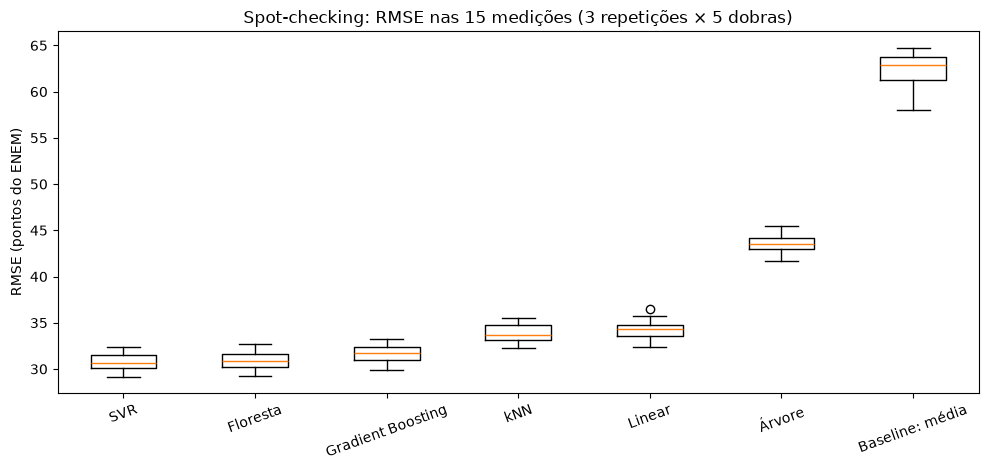

In [8]:
order = summary.index.tolist()
rmse_by_algorithm = [results.loc[results["algoritmo"] == name, "rmse"] for name in order]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.boxplot(rmse_by_algorithm, tick_labels=order)
ax.set_ylabel("RMSE (pontos do ENEM)")
ax.set_title("Spot-checking: RMSE nas 15 medições (3 repetições × 5 dobras)")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "spot_checking_rmse.png", dpi=150)
plt.show()

### Como ler

- **RMSE/MAE** estão em pontos do ENEM. O **baseline da média** tem RMSE ≈ desvio do alvo (≈ 62): todo algoritmo útil precisa ficar abaixo.
- O **desvio** é a variação entre as 15 medições. Ele mistura a diferença entre dobras (municípios diferentes) e entre repetições (sorteios diferentes).
- Como todos os algoritmos usam as **mesmas partições**, a comparação é **pareada**: o que importa para a decisão é a diferença dentro da mesma partição, que a análise estatística da seção 6 usa.
- O tempo é de **uma dobra** e depende da máquina; serve para a ordem de grandeza (custo de otimizar depois), não como valor absoluto.

## 6. Análise estatística

Seguimos a Aula 08 (*Comparação de modelos*): com vários algoritmos e medidas pareadas, se as suposições do ANOVA não forem atendidas usa-se o **teste de Friedman** (não paramétrico, sem exigir normalidade); se rejeitar a hipótese nula, o **teste de Nemenyi** compara os algoritmos em pares.

- **Unidade de análise:** cada uma das 15 partições (repetição × dobra) é um **bloco**; dentro dele, os algoritmos são ordenados pelo RMSE (posto 1 = menor erro).
- **Fora do teste:** o *baseline* da média. Ele é só um piso, e incluí-lo inflaria a diferença global sem informar nada sobre a escolha entre algoritmos.
- **H0 do Friedman:** todos os algoritmos têm a mesma distribuição de postos. **α = 0,05.**

In [9]:
comparison = compare_algorithms(results[results["algoritmo"] != "Baseline: média"])
print(f"Friedman: χ² = {comparison['friedman_statistic']:.2f}, p = {comparison['friedman_p']:.2e}")
comparison["ranks"].to_frame()

Friedman: χ² = 73.10, p = 2.32e-14


,posto médio
algoritmo,
SVR,1.07
Floresta,1.93
Gradient Boosting,3.00
kNN,4.20
Linear,4.80
Árvore,6.00


### Pós-teste de Nemenyi

Dois algoritmos diferem se seus **postos médios** distam pelo menos a **diferença crítica** (Demšar, 2006), com *k* algoritmos, *N* blocos e $q_\alpha$ tabelado (α = 0,05):

$$CD = q_\alpha \sqrt{\frac{k(k+1)}{6N}}$$

In [10]:
print(f"CD = {comparison['critical_difference']:.3f} postos")
comparison["significant_pairs"]

CD = 1.947 postos


,A,B,diferença de postos
0,SVR,Árvore,4.93
1,Floresta,Árvore,4.07
2,SVR,Linear,3.73
3,SVR,kNN,3.13
4,Gradient Boosting,Árvore,3.00
5,Floresta,Linear,2.87
6,Floresta,kNN,2.27


### Cuidados na leitura dos p-valores

- As 15 medições **não são independentes**: os conjuntos de treino se sobrepõem (~75% entre dobras) e as repetições reembaralham os mesmos municípios. A variância é subestimada e os **p-valores são otimistas** (Nadeau & Bengio, 2003; Dietterich, 1998, citado na Aula 08).
- Servem como **triagem** para escolher o que otimizar, não para afirmar superioridade. Confira também a diferença em pontos de RMSE.

Referências: Demšar, J. (2006). *Statistical comparisons of classifiers over multiple data sets.* JMLR 7:1-30. · Nadeau, C. & Bengio, Y. (2003). *Inference for the generalization error.* Machine Learning 52:239-281. · Dietterich, T. (1998). *Approximate statistical tests for comparing supervised classification learning algorithms.* Neural Computation 10(7).

## 7. Conclusões

- Todos os algoritmos ficam abaixo do baseline da média (RMSE 62,35); a árvore sem poda é a que menos se afasta (43,51).
- Ranking por RMSE: SVR (30,77) < Floresta (30,99) < Gradient Boosting (31,65) < kNN (33,91) < Linear (34,24) < Árvore (43,51). Do linear ao SVR a diferença é de ≈ 3,5 pontos.
- O Friedman rejeita H0 (p ≈ 2e-14). Pelo Nemenyi (CD ≈ 1,95), SVR e Floresta são melhores que Linear e kNN; SVR, Floresta e Gradient Boosting **não se separam** entre si, e Gradient Boosting não se separa de kNN e Linear.
- Custo por treino: SVR ≈ 6,4 s, Floresta ≈ 1,1 s, Gradient Boosting ≈ 2,2 s (medidos nesta execução; variam com a máquina): nenhum inviabiliza a otimização.
- [ ] Decisão do grupo: quais levar à nested CV (os dados acima apontam SVR, Floresta e Gradient Boosting; kNN e Linear ficam como referência).

**Limitações:** hiperparâmetros padrão favorecem algoritmos pouco sensíveis a eles, então o ranking pode mudar após o ajuste; os p-valores são otimistas (seção 6).

## Ambiente de execução

Registro das versões usadas, para conferir com `uv.lock`.

In [11]:
import platform

import scipy
import sklearn

print("Python      ", platform.python_version())
for lib in (np, pd, scipy, sklearn):
    print(f"{lib.__name__:<12}", lib.__version__)
print("Plataforma  ", platform.platform())

Python       3.12.13
numpy        2.5.4
pandas       3.0.6
scipy        1.18.1
sklearn      1.9.1
Plataforma   macOS-27.2-arm64-arm-64bit
